# Dual-FEG: numerical evidence and Lyapunov discovery

Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $R\geq0$, $A(x_\star)=0$, and $\|x_{0}-x_\star\|^2\leq R^2$. Fix an integer horizon $N\geq1$, set $z_{0}=0$ and $\alpha=1/L$. For $k=0,\ldots,N-1$:
$$x_{k+1/2}=x_{k}-\alpha z_{k}-\alpha A(x_{k}),$$
$$x_{k+1}=x_{k+1/2}-\frac{N-k-1}{N-k}\alpha\big(A(x_{k+1/2})-A(x_{k})\big),$$
$$z_{k+1}=\frac{N-k-1}{N-k}z_{k}-\frac{A(x_{k+1/2})}{N-k}.$$

The input leaves the performance metric unknown. We select the natural final residual $\|A(x_{N})\|^2$ and prove the uniform bound $4L^2R^2/N^2$. The PEP uses pairwise monotonicity and Lipschitz inequalities; its optimum is an upper relaxation bound, with no interpolation sufficiency claim.

## Proof Statement

### Theorem
Let $A$ be a monotone, $L$-Lipschitz operator on a real finite-dimensional Euclidean space, with $L>0$, $A(x_{\star})=0$, and $\|x_{0}-x_{\star}\|^{2}\leq R^{2}$ for $R\geq0$. For any integer $N\geq1$, run the displayed Dual-FEG recurrence with $z_{0}=0$ and $\alpha=1/L$. Put $g_{N}=A(x_{N})$. The following potential, anchored at the final point, is nonincreasing:
$$V_{0}=0,$$
$$V_{k}=-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle+\frac{4L}{N-k}\langle g_{N},x_{k}-x_{N}\rangle-4\langle g_{N},z_{k}\rangle+\frac{4L}{N-k}\langle x_{k}-x_{N},z_{k}\rangle-2\|z_{k}\|^{2},\qquad 1\leq k<N,$$
$$V_{N}=2\|g_{N}\|^{2}-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle,$$
and the final residual satisfies
$$\boxed{\|A(x_{N})\|^{2}\leq\frac{4L^{2}R^{2}}{N^{2}}.}$$
The formula for $V_{N}$ applies also when $N=1$; the interior range is then empty.

### Proof outline
Use the explicitly defined potential
$$V_{0}=0,$$
$$V_{k}=-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle+\frac{4L}{N-k}\langle g_{N},x_{k}-x_{N}\rangle-4\langle g_{N},z_{k}\rangle+\frac{4L}{N-k}\langle x_{k}-x_{N},z_{k}\rangle-2\|z_{k}\|^{2},\qquad 1\leq k<N,$$
$$V_{N}=2\|g_{N}\|^{2}-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle,$$
For $0\leq k\leq N-2$, write $m=N-k$ and $y_{k}=x_{k+1/2}$. Define
$$M_{k}=-\langle x_{N}-y_{k},g_{N}-A(y_{k})\rangle\leq0,$$
$$Q_{k}=\|A(x_{k})-A(y_{k})\|^{2}-L^{2}\|x_{k}-y_{k}\|^{2}\leq0.$$
The exact recurrence identity is
$$V_{k+1}-V_{k}=\frac{4L}{m(m-1)}M_{k}+\frac{2}{m^{2}}Q_{k}\leq0.$$
At $k=0$, the same formula is verified separately with $z_{0}=0$ and $V_{0}=0$. At the terminal step, $x_{N}=x_{N-1}-(z_{N-1}+A(x_{N-1}))/L$, and
$$Q_{N-1}=\|A(x_{N-1})-g_{N}\|^{2}-L^{2}\|x_{N-1}-x_{N}\|^{2}\leq0,$$
$$V_{N}-V_{N-1}=2Q_{N-1}\leq0.$$
For $N=1$, direct substitution gives $V_{1}=2Q_{0}\leq0$. Hence $V_{N}\leq V_{0}=0$ in every case.

Finally let
$$M_{\star}=-\langle x_{N}-x_{\star},g_{N}\rangle\leq0,\qquad S=\left\|\frac{2L}{N}(x_{0}-x_{\star})-g_{N}\right\|^{2}\geq0.$$
The exact normalized boundary identity is
$$\|g_{N}\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}=V_{N}+\frac{4L}{N}M_{\star}-S+\frac{4L^{2}}{N^{2}}\big(\|x_{0}-x_{\star}\|^{2}-R^{2}\big)\leq0.$$
All multipliers are nonnegative on their stated ranges. This proof uses no division by $R$ or $\|g_{N}\|$, so it includes $R=0$ and zero residuals.

In [1]:
import sys
from pathlib import Path

notebook_dir = Path.cwd().resolve()
REPO_ROOT = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(REPO_ROOT), str(notebook_dir), str(notebook_dir / "supplementary")]

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pepflow as pf
import sympy as sp

## Operator and parameters

In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

## Algorithm and PEP setup
The exact rational recurrence below includes the terminal zero factor and the squared radius normalization.

In [4]:
def make_ctx_dual_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    """Encode the supplied fixed-horizon recurrence using exact ratios."""
    N = int(N)
    if N < 1:
        raise ValueError("N must be positive")
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    z = pf.Vector.zero().add_tag("z_0")
    for k in range(N):
        ax = A(x).add_tag(f"g_{k}")
        half = (x - z / L - ax / L).add_tag(f"x_half_{k}")
        ahalf = A(half).add_tag(f"h_{k}")
        ratio = sp.Rational(N - k - 1, N - k)
        x = (half - ratio * (ahalf - ax) / L).add_tag(f"x_{k + 1}")
        z = (ratio * z - ahalf / (N - k)).add_tag(f"z_{k + 1}")
    A(x).add_tag(f"g_{N}")
    return ctx


def get_pep_setup(N, params):
    """Standard setup interface, with R interpreted as a distance radius."""
    ctx = make_ctx_dual_feg(f"dual_feg_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A

In [5]:
ctx, pb, operator = get_pep_setup(4, {"L": 1, "R": 1})
print("Context built for N=4; metric:", pb.performance_metric)
print("Initial normalization:", pb.init_conditions[0])

Context built for N=4; metric: |g_4|^2
Initial normalization: ScalarConstraint(lhs=|x_0-x_star|^2, rhs=R**2, cmp=<Comparator.LE: 'LE'>, name='initial_condition', associated_dual_var_constraints=[])


## Numerical evidence
The required sweep was run once at $L=R=1$, with CLARABEL defaults. This cell reuses that sweep. Scaling of the recurrence and residual gives the proposed $L^2R^2$ factor. The $N=2$ solve returned `optimal_inaccurate`; all other horizons returned `optimal`.

N=1: 1.9999999892 (optimal)
N=2: 0.9999998678 (optimal_inaccurate)
N=3: 0.4444444571 (optimal)
N=4: 0.2500000046 (optimal)
N=5: 0.1600000090 (optimal)
N=6: 0.1111111159 (optimal)
N=7: 0.0816326561 (optimal)
N^2 times PEP values: [1.99999999 3.99999947 4.00000011 4.00000007 4.00000022 4.00000017
 4.00000015]


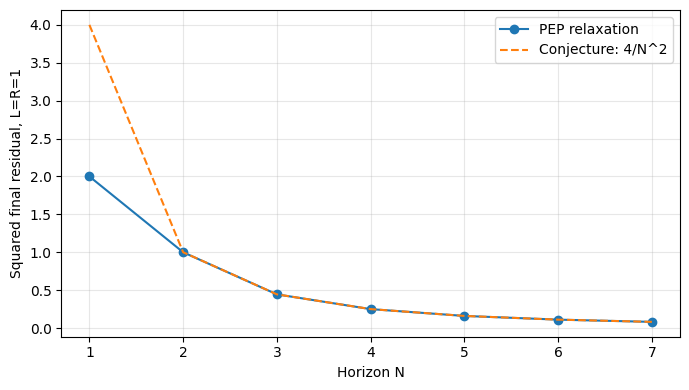

In [6]:
sweep = json.loads((notebook_dir / "supplementary/b1_sweep.json").read_text())
ns = np.array([row["N"] for row in sweep])
values = np.array([row["opt_value"] for row in sweep])
for row in sweep:
    print(f"N={row['N']}: {row['opt_value']:.10f} ({row['solver_status']})")
print("N^2 times PEP values:", ns**2 * values)
plt.figure(figsize=(7, 4))
plt.plot(ns, values, "o-", label="PEP relaxation")
plt.plot(ns, 4 / ns**2, "--", label="Conjecture: 4/N^2")
plt.xlabel("Horizon N")
plt.ylabel("Squared final residual, L=R=1")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The observed values are $2,1,4/9,1/4,4/25,1/9,4/49$ up to solver accuracy. For $N\geq2$ in this sweep they match $4/N^2$; $N=1$ lies strictly below that curve. We retain the simple uniform conjecture
$$\|A(x_{N})\|^2\leq\frac{4L^2R^2}{N^2}.$$
This is not yet a theorem. The subsequent blocks must verify its certificate and exact Lyapunov proof.

## Full-PEP certificate
A dense primal solve and two fresh sparse primal solves used CLARABEL defaults. The first sparsification dropped multipliers below $10^{-6}$. Its dominant pattern suggested the selected structural relaxation below. All saved multipliers, Gram dual, bound, and coordinates belong to the same selected solve. The numerical certificate is verified; global analytic and Lyapunov proofs remain pending.

In [7]:
dense = json.loads((notebook_dir / "state/dual_feg_dense.json").read_text())
b2 = json.loads((notebook_dir / "state/dual_feg_b2.json").read_text())
print("Dense optimum:", dense["opt_value"])
print("Selected optimum:", b2["opt_value"])
print("Dense-selected gap:", abs(dense["opt_value"] - b2["opt_value"]))
print("Basis:", b2["basis_vectors"])
for group in dense["lambda_groups"]:
    names = [
        name
        for name, meta in dense["constraint_metadata"].items()
        if meta["group"] == group
    ]
    important = {
        name: dense["named_dual_values"][name]
        for name in names
        if abs(dense["named_dual_values"][name]) > 1e-5
    }
    print("Dense", group, important)
print("Dense S eigenvalues:", np.linalg.eigvalsh(dense["S_matrix"]))

Dense optimum: 0.2500000046002989
Selected optimum: 0.24999999957831157
Dense-selected gap: 5.0219873537482584e-09
Basis: ['x_0', 'x_star', 'g_0', 'h_0', 'g_1', 'h_1', 'g_2', 'h_2', 'g_3', 'h_3', 'g_4']
Dense Monotone Operator Inequality {'A monotone:x_4,x_half_0': 0.33333699736027184, 'A monotone:x_4,x_half_1': 0.666669331538738, 'A monotone:x_4,x_half_2': 2.000010192178649, 'A monotone:x_4,x_half_3': 0.33832427433590306, 'A monotone:x_4,x_star': 0.9999921878524, 'A monotone:x_half_1,x_half_3': 1.8788587531427068e-05, 'A monotone:x_half_2,x_half_3': 5.411008991968012e-05, 'A monotone:x_half_3,x_star': 3.997668662374072e-05}
Dense Lipschitz Continuous Inequality {'A Lipschitz:x_0,x_half_0': 0.12500402900061378, 'A Lipschitz:x_1,x_half_1': 0.22222937551605315, 'A Lipschitz:x_2,x_half_2': 0.5000160737774202, 'A Lipschitz:x_3,x_4': 2.000025672670334, 'A Lipschitz:x_3,x_half_3': 3.864796544611015e-05, 'A Lipschitz:x_4,x_half_3': 0.599664203523733}
Dense S eigenvalues: [1.23331338e-11 3.991

### Selected sparse pattern
Retain monotonicity between $x_{N}$ and $x_\star$, and between $x_{N}$ and $x_{k+1/2}$ for $0\leq k<N-1$. Retain Lipschitz continuity between $x_{k}$ and $x_{k+1/2}$ for $0\leq k<N-1$, and between $x_{N-1}$ and $x_{N}$. The terminal half-point and final point coincide in the recurrence; redundant interpolation constraints involving their separately tracked outputs need not be retained for this upper-bound certificate.

In [8]:
n = b2["N_verify"]
keep = {"initial_condition", f"A monotone:x_{n},x_star", f"A Lipschitz:x_{n - 1},x_{n}"}
for k in range(n - 1):
    keep.add(f"A monotone:x_{n},x_half_{k}")
    keep.add(f"A Lipschitz:x_{k},x_half_{k}")
assert set(b2["relaxed_constraints"]) == set(b2["named_dual_values"]) - keep
print("Retained interpolation constraints:", len(keep) - 1)
print("Dropped interpolation constraints:", len(b2["relaxed_constraints"]))
for name in sorted(keep):
    print(name, b2["named_dual_values"][name])
assert abs(b2["opt_value"] - dense["opt_value"]) < 1e-5

Retained interpolation constraints: 8
Dropped interpolation constraints: 82
A Lipschitz:x_0,x_half_0 0.12500276495586313
A Lipschitz:x_1,x_half_1 0.22222713556378462
A Lipschitz:x_2,x_half_2 0.5000110541262774
A Lipschitz:x_3,x_4 2.0000442124963476
A monotone:x_4,x_half_0 0.3333407032255785
A monotone:x_4,x_half_1 0.6666814053692469
A monotone:x_4,x_half_2 2.0000442138148378
A monotone:x_4,x_star 1.0000221055205096
initial_condition 0.2500000005286884


### Initial closed-form search
No pre-existing target references were consulted. Fractions of the selected multipliers suggest the formulas below, with $m=N-k$. These are numerically supported candidates, not an arbitrary-horizon proof.

In [9]:
def candidate_multipliers(n, lipschitz=sp.S.One):
    result = {
        "initial_condition": 4 * lipschitz**2 / sp.Integer(n) ** 2,
        f"A monotone:x_{n},x_star": 4 * lipschitz / n,
        f"A Lipschitz:x_{n - 1},x_{n}": sp.S(2),
    }
    for k in range(n - 1):
        remaining = sp.Integer(n - k)
        result[f"A monotone:x_{n},x_half_{k}"] = (
            4 * lipschitz / (remaining * (remaining - 1))
        )
        result[f"A Lipschitz:x_{k},x_half_{k}"] = 2 / remaining**2
    return result


def candidate_square(ctx, n, lipschitz=sp.S.One):
    return (2 * lipschitz / n * (ctx["x_0"] - ctx["x_star"]) - ctx[f"g_{n}"]) ** 2

In [10]:
candidate = candidate_multipliers(n)
errors = {
    name: abs(float(value) - b2["named_dual_values"][name])
    for name, value in candidate.items()
}
assert max(errors.values()) <= 1e-4
print("Maximum candidate multiplier error:", max(errors.values()))
for group, display in b2["lambda_groups"].items():
    matrix = np.zeros_like(display["matrix"], dtype=float)
    for i, row in enumerate(display["row_names"]):
        for j, col in enumerate(display["col_names"]):
            prefix = (
                "A monotone"
                if group == "Monotone Operator Inequality"
                else "A Lipschitz"
            )
            matrix[i, j] = float(candidate.get(f"{prefix}:{row},{col}", 0))
    print("Candidate", group)
    pf.pprint_labeled_matrix(
        matrix, display["row_names"], display["col_names"], precision=5
    )

Maximum candidate multiplier error: 4.4213814837767984e-05
Candidate Monotone Operator Inequality


<IPython.core.display.Math object>

Candidate Lipschitz Continuous Inequality


<IPython.core.display.Math object>

### Selected numerical remainder and certificate check
The saved reverse-LDL factorization keeps every factor and block, including small numerical terms; no near-zero contribution is discarded. With rows $E_{i}$ representing linear forms $\ell_{i}$, the remainder is $S_{\rm num}=\sum_{ij}D_{ij}\langle\ell_{i},\ell_{j}\rangle$ and its Gram matrix is $E^TDE$.

Every active scalar inequality has residual $r_{c}\leq0$. The complete sign convention is
$$\mathrm{metric}-\mathrm{bound}-\sum_{c}\lambda_{c} r_{c}+S_{\rm num}=0.$$
Nonnegative multipliers and $S\succeq0$ imply the numerical upper bound. The initial radius residual, all interpolation families, and the constant coordinate are included.

In [11]:
def inventory(ctx, pb):
    entries = [(c, "initial", None, None) for c in pb.init_conditions]
    for owner in [*ctx.func_to_triplets, *ctx.oper_to_duplets]:
        groups = ctx.get_constraint_data(owner)
        entries.extend(
            (c, "interpolation", str(owner), str(group))
            for group, constraints in groups.sc_dict.items()
            for c in constraints
        )
        entries.extend(
            (c, "interpolation", str(owner), str(group))
            for group, c in groups.psd_dict.items()
        )
    assert len({c.name for c, *_ in entries}) == len(entries)
    return entries


def verify_certificate(state, get_setup, dense_value):
    params = json.loads(state["params_json"])
    ctx, pb, _ = get_setup(state["N_verify"], params)
    basis = ctx.basis_vectors()
    assert [str(v) for v in basis] == state["basis_vectors"]
    assert [str(v) for v in ctx.basis_scalars()] == state["basis_scalars"]
    assert state["S_row_names"] == state["S_col_names"] == state["basis_vectors"]
    entries = inventory(ctx, pb)
    assert (
        {c.name for c, *_ in entries}
        == set(state["named_dual_values"])
        == set(state["constraint_metadata"])
    )
    pm = pf.ExpressionManager(ctx, resolve_parameters=params)
    weighted = pf.Scalar.zero()
    minimum_duals = []
    for c, origin, owner, group in entries:
        meta = state["constraint_metadata"][c.name]
        assert (
            meta["origin"],
            meta["owner"],
            meta["group"],
            meta["comparator"],
            meta["kind"],
        ) == (origin, owner, group, c.cmp.value, "scalar")
        value = state["named_dual_values"][c.name]
        if meta["relaxed"]:
            assert value is None and c.name in state["relaxed_constraints"]
            continue
        assert value is not None and np.isfinite(value)
        residual = c.lhs - c.rhs
        if c.cmp == pf.Comparator.GE:
            residual = -residual
        weighted += value * residual
        if c.cmp != pf.Comparator.EQ:
            minimum_duals.append(value)
    S = np.asarray(state["S_matrix"], dtype=float)
    D = np.asarray(state["numerical_decomposition"]["D"], dtype=float)
    E = np.asarray(state["numerical_decomposition"]["ell_coords"], dtype=float)
    ell = [
        sum((float(a) * v for a, v in zip(row, basis)), pf.Vector.zero()) for row in E
    ]
    S_numeric = sum(
        (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)),
        pf.Scalar.zero(),
    )
    diff = pb.performance_metric - state["opt_value"] - weighted + S_numeric
    checked = pm.eval_scalar(diff)

    def max_abs(values):
        return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))

    residuals = dict(
        identity_gram_max_abs=max_abs(checked.inner_prod_coords),
        identity_func_max_abs=max_abs(checked.func_coords),
        identity_offset_abs=max_abs(checked.offset),
        S_reconstruction_max_abs=max_abs(E.T @ D @ E - S),
        dense_relaxed_gap=abs(state["opt_value"] - dense_value),
        conjecture_gap=abs(
            state["opt_value"]
            - 4 * params["L"] ** 2 * params["R"] ** 2 / state["N_verify"] ** 2
        ),
        minimum_scalar_inequality_dual=min(minimum_duals, default=0.0),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh((S + S.T) / 2).min()),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    tolerances = dict(
        identity_atol=1e-5,
        identity_rtol=0.0,
        reconstruction_atol=1e-4,
        reconstruction_rtol=1e-5,
        dual_tol=1e-6,
        psd_tol=1e-6,
        dense_opt_atol=1e-5,
    )
    passed = (
        state["certificate_provenance"]["solver_status"] == "optimal"
        and np.all(np.isfinite(S))
        and np.allclose(S, S.T, atol=1e-6, rtol=0)
        and all(
            residuals[k] <= 1e-5
            for k in [
                "identity_gram_max_abs",
                "identity_func_max_abs",
                "identity_offset_abs",
            ]
        )
        and np.allclose(E.T @ D @ E, S, atol=1e-4, rtol=1e-5)
        and residuals["dense_relaxed_gap"] < 1e-5
        and residuals["conjecture_gap"] < 1e-5
        and residuals["minimum_scalar_inequality_dual"] >= -1e-6
        and residuals["minimum_S_eigenvalue"] >= -1e-6
    )
    return (
        dict(tolerances=tolerances, residuals=residuals, passed=bool(passed)),
        ctx,
        pm,
        checked,
    )

In [12]:
checks, certificate_ctx, certificate_pm, residual = verify_certificate(
    b2, get_pep_setup, dense["opt_value"]
)
assert checks["passed"]
print("Numerical certificate checks:", checks)
print("Selected S eigenvalues:", np.linalg.eigvalsh(b2["S_matrix"]))
D = np.array(b2["numerical_decomposition"]["D"])
E = np.array(b2["numerical_decomposition"]["ell_coords"])
print("LDL diagonal:", np.diag(D))
pf.pprint_labeled_matrix(
    E, [f"ell_{i}" for i in range(len(E))], b2["basis_vectors"], precision=5
)
pf.pprint_labeled_matrix(
    np.asarray(residual.inner_prod_coords, dtype=float),
    b2["basis_vectors"],
    precision=9,
)
print("Selected numerical S")
pf.pprint_labeled_matrix(
    np.asarray(b2["S_matrix"], dtype=float), b2["basis_vectors"], precision=6
)

Numerical certificate checks: {'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0.0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 1.377260850206261e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 9.503768605423346e-10, 'S_reconstruction_max_abs': 5.551115123125783e-17, 'dense_relaxed_gap': 5.0219873537482584e-09, 'conjecture_gap': 4.2168843417123014e-10, 'minimum_scalar_inequality_dual': 0.12500276495586313, 'minimum_S_eigenvalue': 2.6151789612983615e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}
Selected S eigenvalues: [2.61517896e-11 3.45630102e-10 5.19558616e-10 6.09961074e-10
 7.26055354e-10 7.26055453e-10 1.06931454e-09 1.57100972e-09
 1.66769911e-09 2.39831664e-09 1.50004421e+00]
LDL diagonal: [1.00004421e+00 7.26055354e-10 7.16849558e-10 9.87931263e-10
 6.14220309e-10 8.12164907e-10 6.49316410e-10 1.69832956e-09
 8.51494320e-1

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r03\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



<IPython.core.display.Math object>

<IPython.core.display.Math object>

Selected numerical S


<IPython.core.display.Math object>

### Candidate square and finite exact identity checks
The rank-one pattern suggests
$$S_{\rm guess}=\left\|\frac{2L}{N}(x_{0}-x_\star)-A(x_{N})\right\|^2.$$
The following code checks its Gram, function-value, and offset coordinates against the selected numerical remainder. It then verifies the complete candidate identity in exact arithmetic at several finite horizons. This does not prove the identity for arbitrary $N$ or parameters.

In [13]:
square_evaluated = certificate_pm.eval_scalar(candidate_square(certificate_ctx, n))
square_error = np.max(
    np.abs(np.asarray(square_evaluated.inner_prod_coords, dtype=float) - b2["S_matrix"])
)
assert square_error <= 1e-4
assert (
    np.max(np.abs(np.asarray(square_evaluated.func_coords, dtype=float)), initial=0)
    == 0
)
assert square_evaluated.offset == 0
print("Candidate square Gram error:", square_error)
pf.pprint_labeled_matrix(
    np.asarray(square_evaluated.inner_prod_coords, dtype=float),
    b2["basis_vectors"],
    precision=5,
)
for horizon in [1, 2, 3, 4, 6]:
    sample_ctx, sample_pb, _ = get_pep_setup(horizon, {"L": sp.S.One, "R": sp.S.One})
    sample_pm = pf.ExpressionManager(
        sample_ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One}
    )
    constraints = {c.name: c for c, *_ in inventory(sample_ctx, sample_pb)}
    weights = candidate_multipliers(horizon)
    weighted = sum(
        (
            value * (constraints[name].lhs - constraints[name].rhs)
            for name, value in weights.items()
        ),
        pf.Scalar.zero(),
    )
    identity = (
        sample_pb.performance_metric
        - sp.Rational(4, horizon**2)
        - weighted
        + candidate_square(sample_ctx, horizon)
    )
    exact = sample_pm.eval_scalar(identity, sympy_mode=True)
    gram = sp.Matrix(exact.inner_prod_coords).applyfunc(sp.simplify)
    assert gram == sp.zeros(*gram.shape)
    assert all(sp.simplify(x) == 0 for x in exact.func_coords)
    assert sp.simplify(exact.offset) == 0
    print(f"N={horizon}: exact Gram/function/offset identity passed")

Candidate square Gram error: 4.421263862464109e-05


<IPython.core.display.Math object>

N=1: exact Gram/function/offset identity passed
N=2: exact Gram/function/offset identity passed
N=3: exact Gram/function/offset identity passed
N=4: exact Gram/function/offset identity passed
N=6: exact Gram/function/offset identity passed


### Block 2 conclusion
The selected numerical certificate passes the identity, PSD, multiplier-sign, normalization, decomposition, and preserved-optimum checks. Candidate formulas match the numerical sample and pass finite exact checks. The unresolved obligation is their arbitrary-horizon analytic validity; `numerical_certificate_verified=True`, `analytic_full_pep_verified=False`, `lyapunov_proof_verified=False`.

### Second complete certificate sample
Block 3 requested a fresh $N=6$ certificate for later rank comparison. The same structural relaxation preserves the dense optimum. The selected main certificate remains $N=4$. The following replay checks all components of the additional saved certificate; rank analysis of this sample belongs to the next B3 continuation.

In [14]:
sample6 = json.loads((notebook_dir / "supplementary/b2-N6.json").read_text())
dense6 = json.loads((notebook_dir / "supplementary/b2-N6-dense.json").read_text())
checks6, _, _, _ = verify_certificate(sample6, get_pep_setup, dense6["opt_value"])
assert checks6["passed"]
print("N=6 dense and sparse bounds:", dense6["opt_value"], sample6["opt_value"])
print("N=6 full numerical checks:", checks6)
print("N=6 candidate comparisons:", sample6["closed_form_search"]["N6_comparison"])

N=6 dense and sparse bounds:

 0.11111111587386419 0.1111111105676805
N=6 full numerical checks: {'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0.0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 1.8649519168148035e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.90246582113474e-10, 'S_reconstruction_max_abs': 1.3877787807814457e-17, 'dense_relaxed_gap': 5.306183686881738e-09, 'conjecture_gap': 5.434306060703165e-10, 'minimum_scalar_inequality_dual': 0.055554999917130206, 'minimum_S_eigenvalue': 1.1840123684563205e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}
N=6 candidate comparisons: {'lambda_max_abs_error': 2.00325141828106e-05, 'S_gram_max_abs_error': 2.0032408179493366e-05, 'comparison_atol': 0.0001, 'passed': True}


## Lyapunov partial sums and ranks
Write $y_{k}=x_{k+1/2}$ and use residuals
$$M_{k}=-\langle x_{N}-y_{k},A(x_{N})-A(y_{k})\rangle\leq0,$$
$$Q_{k}=\|A(x_{k})-A(y_{k})\|^2-L^2\|x_{k}-y_{k}\|^2\leq0.$$
For $k<N-1$, group the selected numerical multipliers as
$$V_{k+1}-V_{k}=\lambda^M_kM_{k}+\lambda^Q_kQ_{k},$$
with $V_{0}=0$. The final increment uses the selected Lipschitz residual between $x_{N-1}$ and $x_{N}$. All weights are nonnegative, so this convention gives $V_{k+1}\leq V_{k}$.

The star monotonicity term and the full PSD remainder are retained as the one interpolation and one PSD boundary terms. The candidate single square approximates the saved remainder at the reconstruction tolerance, but its error exceeds the stricter coverage tolerance. Therefore the construction retains the full numerical $S$ as one PSD boundary block, without truncating any term.

The recomputed $N=4$ and $N=6$ samples both have interior rank 4. Excluding only $V_{0}$ and $V_{N}$ leaves at least three indices at each horizon. This is finite-sample structural evidence, not an arbitrary-horizon theorem. The full Gram matrix uses the unscaled setup coordinate order and absolute rank tolerance $10^{-4}$; no singular value lies in $[0.5\times10^{-4},2\times10^{-4}]$.

In [15]:
import hashlib


def certificate_id(state):
    keys = (
        "N_verify",
        "params_json",
        "relaxed_constraints",
        "S_matrix",
        "S_row_names",
        "S_col_names",
        "basis_vectors",
        "basis_scalars",
        "opt_value",
        "tau_sol",
        "tau_name",
        "named_dual_values",
        "constraint_metadata",
        "normalization",
        "certificate_provenance",
        "numerical_checks",
        "numerical_decomposition",
    )
    return hashlib.sha256(
        json.dumps(
            {k: state[k] for k in keys},
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False,
        ).encode()
    ).hexdigest()


def replay_certificate(certificate, get_setup, root, dense_value):
    assert certificate_id(certificate) == certificate["certificate_id"]
    assert certificate["closed_form_search"]["completed"]
    assert certificate["certificate_provenance"]["pep_type"] == "primal"
    for relative, expected in certificate["certificate_provenance"][
        "source_hashes"
    ].items():
        path = (Path(root) / relative).resolve()
        assert path.is_relative_to(Path(root).resolve())
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected
    assert (
        Path(pf.__file__).resolve()
        == Path(root).resolve() / "supplementary/approved/pepflow/__init__.py"
    )
    assert (
        certificate["normalization"]["tau_name"]
        == certificate["tau_name"]
        == "initial_condition"
    )
    assert (
        abs(
            certificate["tau_sol"]
            - certificate["named_dual_values"]["initial_condition"]
        )
        <= 1e-6
    )
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    checks, ctx, pm, checked = verify_certificate(certificate, get_setup, dense_value)
    assert checks["passed"]
    return checks, ctx, pm

In [16]:
def full_psd_piece(certificate, ctx, pm):
    """Keep the full numerical S as one boundary PSD block, without truncation."""
    basis = ctx.basis_vectors()
    matrix = np.asarray(certificate["S_matrix"], dtype=float)
    S_scalar = sum(
        (
            float(matrix[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(matrix.shape)
        ),
        pf.Scalar.zero(),
    )
    value = pm.eval_scalar(S_scalar)
    assert np.allclose(
        np.asarray(value.inner_prod_coords, dtype=float), matrix, atol=1e-5, rtol=0
    )
    assert np.allclose(value.func_coords, 0, atol=1e-5, rtol=0)
    assert abs(float(value.offset)) <= 1e-5
    assert np.linalg.eigvalsh((matrix + matrix.T) / 2).min() >= -1e-6
    return S_scalar, {"full_S": S_scalar}

In [17]:
def build_partial_sums(certificate, ctx, pb, pm, S_scalar, S_piece_terms):
    n = certificate["N_verify"]
    entries = inventory(ctx, pb)
    group_terms = {}
    for c, origin, _, _ in entries:
        d = certificate["named_dual_values"][c.name]
        if origin == "interpolation" and d is not None:
            assert c.cmp == pf.Comparator.LE and d >= -1e-6
            group_terms[c.name] = d * (c.lhs - c.rhs)
    term_assignment = {f"A monotone:x_{n},x_star": "boundary"}
    for k in range(n - 1):
        term_assignment[f"A monotone:x_{n},x_half_{k}"] = k
        term_assignment[f"A Lipschitz:x_{k},x_half_{k}"] = k
    term_assignment[f"A Lipschitz:x_{n - 1},x_{n}"] = n - 1
    S_assignment = {"full_S": "boundary"}
    assert set(term_assignment) == set(group_terms)
    assert set(S_assignment) == set(S_piece_terms)
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    increments = []
    for k in range(n):
        increment = sum(
            (group_terms[name] for name, step in term_assignment.items() if step == k),
            pf.Scalar.zero(),
        )
        partial_sum += increment
        lyap.append(partial_sum)
        increments.append(increment)
    rank_tolerance = 1e-4
    rank_left, rank_right = 1, 1
    evaluated = [pm.eval_scalar(v) for v in lyap]
    matrices = [np.asarray(v.inner_prod_coords, dtype=float) for v in evaluated]
    singular_values = [np.linalg.svd(m, compute_uv=False).tolist() for m in matrices]
    ranks = [int(np.linalg.matrix_rank(m, tol=rank_tolerance)) for m in matrices]
    for k, rank in enumerate(ranks):
        print(f"rank V_{k}: {rank}")
        if k == 0:
            print()
    retained = ranks[rank_left : n + 1 - rank_right]
    print(
        "Interior rank is constant at this N:",
        len(retained) >= 3 and len(set(retained)) == 1,
        "boundary exclusions:",
        (rank_left, rank_right),
    )
    boundary_names = [
        name for name, step in term_assignment.items() if step == "boundary"
    ]
    boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
    assert len(boundary_names) <= 1 and len(boundary_S) <= 1
    leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
    leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
    coverage = (
        lyap[n] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
    )
    pieces_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    checked_residuals = {}
    expressions = [("coverage", coverage), ("S_pieces", pieces_diff)]
    expressions += [
        (f"increment_{k}", lyap[k + 1] - lyap[k] - increments[k]) for k in range(n)
    ]
    for label, expression in expressions:
        v = pm.eval_scalar(expression)
        residual = max(
            float(
                np.max(np.abs(np.asarray(v.inner_prod_coords, dtype=float)), initial=0)
            ),
            float(np.max(np.abs(np.asarray(v.func_coords, dtype=float)), initial=0)),
            abs(float(v.offset)),
        )
        assert residual <= 1e-5
        checked_residuals[label] = residual
    # Each increment is a sum of nonnegative multipliers times residuals <= 0.
    # Thus the intended convention is V_{k+1} <= V_k, with V_0=0.
    observation = dict(
        N=n,
        certificate_id=certificate["certificate_id"],
        recipe_id="terminal_anchor_monotonicity_and_step_lipschitz__S_boundary",
        rank_profile=ranks,
        singular_values=singular_values,
        rank_convention=dict(
            tolerance=rank_tolerance,
            scaling="unscaled Gram matrix",
            coordinate_order="setup basis_vectors order",
        ),
        rank_credible=not any(
            0.5e-4 <= s <= 2e-4 for row in singular_values for s in row
        ),
        certificate_checked=True,
        grouping_checked=True,
        coverage_residuals=checked_residuals,
        lyap_inner_prod_coords=[m.tolist() for m in matrices],
        lyap_func_coords=[
            np.asarray(v.func_coords, dtype=float).tolist() for v in evaluated
        ],
        lyap_offsets=[float(v.offset) for v in evaluated],
        grouping_coverage=dict(
            constraint_assignment=term_assignment,
            S_assignment=S_assignment,
            normalization_constraint="initial_condition",
            boundary_constraints=boundary_names,
            boundary_S=boundary_S,
            omitted_constraints=[],
            checked=True,
        ),
    )
    return lyap, observation


rank_samples = []
selected_lyap = None
for sample_path, dense_path in [
    ("state/dual_feg_b2.json", "state/dual_feg_dense.json"),
    ("supplementary/b2-N6.json", "supplementary/b2-N6-dense.json"),
]:
    certificate = json.loads((notebook_dir / sample_path).read_text())
    sample_dense = json.loads((notebook_dir / dense_path).read_text())
    replay_checks, _, _ = replay_certificate(
        certificate, get_pep_setup, notebook_dir, sample_dense["opt_value"]
    )
    ctx, pb, _ = get_pep_setup(
        certificate["N_verify"], json.loads(certificate["params_json"])
    )
    pm = pf.ExpressionManager(
        ctx, resolve_parameters=json.loads(certificate["params_json"])
    )
    S_scalar, S_piece_terms = full_psd_piece(certificate, ctx, pm)
    print("Horizon:", certificate["N_verify"])
    lyap, observation = build_partial_sums(
        certificate, ctx, pb, pm, S_scalar, S_piece_terms
    )
    assert observation["rank_credible"] and observation["grouping_checked"]
    print(
        "Maximum coverage/increment residual:",
        max(observation["coverage_residuals"].values()),
    )
    rank_samples.append(observation)
    if certificate["N_verify"] == b2["N_verify"]:
        selected_lyap = lyap
rank_left, rank_right = 1, 1
retained_profiles = [
    sample["rank_profile"][rank_left : sample["N"] + 1 - rank_right]
    for sample in rank_samples
]
assert all(
    len(profile) >= 3 and len(set(profile)) == 1 for profile in retained_profiles
)
assert len({profile[0] for profile in retained_profiles}) == 1
assert len({sample["N"] for sample in rank_samples}) == 2
assert all(
    sample["recipe_id"] == rank_samples[0]["recipe_id"]
    and sample["rank_convention"] == rank_samples[0]["rank_convention"]
    for sample in rank_samples
)
print(
    "Cross-horizon confirmation: rank 4 at N=4 and N=6; exclusions (1,1), absolute tolerance 1e-4."
)

Horizon: 4


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Maximum coverage/increment residual: 5.551115123125783e-17


Horizon: 6
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Maximum coverage/increment residual: 1.1102230246251565e-16
Cross-horizon confirmation: rank 4 at N=4 and N=6; exclusions (1,1), absolute tolerance 1e-4.


### Block 3 conclusion
The selected $N=4$ profile is $[0,4,4,4,2]$, and the confirming $N=6$ profile is $[0,4,4,4,4,4,2]$. All interpolation contributions are assigned, with exactly one star monotonicity term and one full PSD block retained at the boundary. No terms are omitted. The terminal rank is 2, and the coverage identities pass in Gram, function-value, and constant coordinates. The numerical certificate remains verified; analytic full-PEP and Lyapunov proofs remain pending.

## Identify the vectors composing the Lyapunov function
We return to the selected $N=4$ certificate, whose interior rank 4 was independently confirmed at $N=6$. All indices, including the zero initial potential and rank-two terminal potential, must reconstruct.

In [18]:
import itertools
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

b3 = json.loads((notebook_dir / "state/dual_feg_b3.json").read_text())
assert b3["rank_search"]["status"] == "confirmed"
rank_evidence = json.loads(
    (notebook_dir / b3["rank_search"]["evidence_path"]).read_text()
)
assert rank_evidence["summary"] == b3["rank_search"]
replay_certificate(b3, get_pep_setup, notebook_dir, dense["opt_value"])
n = b3["N_verify"]
ctx, pb, _ = get_pep_setup(n, json.loads(b3["params_json"]))
pm = pf.ExpressionManager(ctx, resolve_parameters=json.loads(b3["params_json"]))
S_scalar, pieces = full_psd_piece(b3, ctx, pm)
lyap, observation = build_partial_sums(b3, ctx, pb, pm, S_scalar, pieces)
assert observation["rank_profile"] == b3["rank_profile"]
for k, value in enumerate(lyap):
    evaluated = pm.eval_scalar(value)
    assert np.allclose(
        np.asarray(evaluated.inner_prod_coords, dtype=float),
        b3["lyap_inner_prod_coords"][k],
        atol=1e-4,
        rtol=1e-5,
    )
    assert np.allclose(
        evaluated.func_coords, b3["lyap_func_coords"][k], atol=1e-4, rtol=1e-5
    )
    assert np.allclose(
        float(evaluated.offset), b3["lyap_offsets"][k], atol=1e-4, rtol=1e-5
    )

rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)


### Candidate-vector scan
Candidates include tagged iterates, operator outputs, auxiliary vectors $z_{k}$, all point-pair differences, and the terminal anchor displacement. Equivalent coordinates and the zero vector are removed, with meaningful derived labels preferred.

In [19]:
pairs = []
for tag in [f"g_{n}"] + [f"z_{k}" for k in range(1, n + 1)]:
    pairs.append((tag, ctx[tag]))
for k in range(n):
    pairs.append((f"x_{k}-x_N", ctx[f"x_{k}"] - ctx[f"x_{n}"]))
for tag in (
    ["x_star"] + [f"x_{k}" for k in range(n + 1)] + [f"x_half_{k}" for k in range(n)]
):
    pairs.append((tag, ctx[tag]))
for v in ctx.basis_vectors():
    pairs.append((str(v), v))
point_tags = [f"x_{k}" for k in range(n + 1)] + ["x_star"]
for a, b in itertools.combinations(point_tags, 2):
    pairs.append((f"{a}-{b}", ctx[a] - ctx[b]))
unique, coords_seen = [], []
for label, vector in pairs:
    coordinate = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coordinate) <= 1e-12 or any(
        np.allclose(coordinate, prev, atol=1e-12, rtol=0) for prev in coords_seen
    ):
        continue
    unique.append((label, vector))
    coords_seen.append(coordinate)
labels = {id(v): label for label, v in unique}
params = json.loads(b3["params_json"])

In [20]:
in_col_by_k = {}
for k in range(n + 1):
    in_col = vectors_in_column_space(
        lyap[k],
        [v for _, v in unique],
        pep_context=ctx,
        resolve_parameters=params,
        rtol=1e-4,
        atol=1e-4,
    )
    in_col_by_k[k] = in_col
    print(f"V_{k} column-space candidates:")
    for v in in_col:
        print("  ", labels[id(v)])

V_0 column-space candidates:
V_1 column-space candidates:
   g_4
   z_1
   x_0-x_N
   x_1-x_N
   g_0
   h_0
   x_0-x_1
V_2 column-space candidates:
   g_4
   z_2
   x_0-x_N
   x_2-x_N
   x_0-x_2
V_3 column-space candidates:
   g_4
   z_3
   x_0-x_N
   x_3-x_N
   g_3
   x_0-x_3
V_4 column-space candidates:
   g_4
   x_0-x_N


### Selected basis pattern
The following exhaustive subset search uses the framework utility and the frozen tolerances. We then adopt the uniform auxiliary-vector basis for interpretability; at $k=N-1$ the sparsest output instead uses the last current operator value. Both choices reconstruct, and the adopted basis avoids a separate penultimate case.

In [21]:
sparse_coefficients = {}
for k in range(n + 1):
    sparse_basis, C = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_col_by_k[k],
        pep_context=ctx,
        resolve_parameters=params,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    assert len(sparse_basis) == b3["rank_profile"][k]
    sparse_coefficients[k] = C
    print(f"k={k}, rank {b3['rank_profile'][k]}")
    print("sparse basis:", [labels[id(v)] for v in sparse_basis])
    print("zero coefficients:", int(np.sum(abs(C) < 1e-6)), "/", C.size)

k=0, rank 0
sparse basis: []
zero coefficients: 0 / 0
k=1, rank 4
sparse basis: ['g_4', 'z_1', 'x_0-x_N', 'x_1-x_N']
zero coefficients: 7 / 16
k=2, rank 4
sparse basis: ['g_4', 'z_2', 'x_0-x_N', 'x_2-x_N']
zero coefficients: 7 / 16


k=3, rank 4
sparse basis: ['g_4', 'x_0-x_N', 'x_3-x_N', 'g_3']
zero coefficients: 10 / 16
k=4, rank 2
sparse basis: ['g_4', 'x_0-x_N']
zero coefficients: 1 / 4


For $1\leq k<N$, adopt the ordered basis
$$\big[A(x_{N}),\ x_{0}-x_{N},\ x_{k}-x_{N},\ z_{k}\big].$$
At $k=0$ the basis is empty; at $k=N$ use $[A(x_{N}),x_{0}-x_{N}]$. These exceptions remain part of the reconstruction and final proof.

In [22]:
def basis_for(ctx, k, n):
    if k == 0:
        return []
    basis = [ctx[f"g_{n}"], ctx["x_0"] - ctx[f"x_{n}"]]
    if k < n:
        basis.extend([ctx[f"x_{k}"] - ctx[f"x_{n}"], ctx[f"z_{k}"]])
    return basis


def basis_labels_for(k, n):
    if k == 0:
        return []
    labels = ["A(x_N)", "x_0-x_N"]
    if k < n:
        labels.extend([f"x_{k}-x_N", f"z_{k}"])
    return labels


def V_k_basis(k):
    return basis_for(ctx, k, n)


def V_k_basis_labels(k):
    return basis_labels_for(k, n)


for k in range(n + 1):
    basis = V_k_basis(k)
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float)
        if basis
        else np.empty((len(ctx.basis_vectors()), 0))
    )
    rank = int(np.linalg.matrix_rank(matrix, tol=1e-7)) if basis else 0
    assert rank == len(basis) == b3["rank_profile"][k]
    print(f"k={k}: rank {rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_1-x_N', 'z_1']
k=2: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_2-x_N', 'z_2']
k=3: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_3-x_N', 'z_3']
k=4: rank 2 basis ['A(x_N)', 'x_0-x_N']


### Coefficient matrices
The interior order is $[A(x_{N}),x_{0}-x_{N},x_{k}-x_{N},z_{k}]$; the terminal order is $[A(x_{N}),x_{0}-x_{N}]$. The symmetric convention is $V_{k}=\sum_{ij}C_{ij}\langle v_{i},v_{j}\rangle$, so off-diagonal entries contribute twice. There are no function-value or constant terms. Candidate formulas remain unproved over the full horizon and parameter domain.

In [23]:
def coeff_pattern(k, n, lipschitz=sp.S.One):
    n = sp.sympify(n)
    if k == 0:
        return sp.zeros(0, 0)
    if k == n:
        return sp.Matrix([[2, -2 * lipschitz / n], [-2 * lipschitz / n, 0]])
    m = n - k
    return sp.Matrix(
        [
            [0, -2 * lipschitz / n, 2 * lipschitz / m, -2],
            [-2 * lipschitz / n, 0, 0, 0],
            [2 * lipschitz / m, 0, 0, 2 * lipschitz / m],
            [-2, 0, 2 * lipschitz / m, -2],
        ]
    )


def numerical_structure(ctx, k, n, coefficients):
    basis = basis_for(ctx, k, n)
    C = coefficients[k]
    # Function-value and constant terms are absent, checked separately below.
    return sum(
        (float(C[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )


def reconstruct_all(certificate, ctx, pm, lyap, cached=None):
    n = certificate["N_verify"]
    params = json.loads(certificate["params_json"])
    coefficients, quadratic_residuals, component_residuals, fit_errors = {}, {}, {}, {}
    for k in range(n + 1):
        basis = basis_for(ctx, k, n)
        target = pm.eval_scalar(lyap[k])
        gram = np.asarray(target.inner_prod_coords, dtype=float)
        B = (
            np.column_stack([pm.eval_vector(v).coords for v in basis]).astype(float)
            if basis
            else np.empty((len(ctx.basis_vectors()), 0))
        )
        rank = int(np.linalg.matrix_rank(B, tol=1e-7)) if basis else 0
        assert rank == len(basis) == int(np.linalg.matrix_rank(gram, tol=1e-4))
        cache_C = None if cached is None else cached.get(k)
        if cache_C is not None and np.linalg.norm(
            B @ cache_C @ B.T - gram, ord="fro"
        ) <= 1e-5 * max(1.0, np.linalg.norm(gram, ord="fro")):
            C = cache_C
        else:
            C = find_symmetric_coefficient_matrix(
                lyap[k],
                basis,
                pep_context=ctx,
                resolve_parameters=params,
                indep_tol=1e-7,
                span_tol=1e-5,
            )
        assert C.shape == (len(basis), len(basis)) and np.array_equal(C, C.T)
        assert np.all(np.isfinite(C))
        residual = float(np.linalg.norm(B @ C @ B.T - gram, ord="fro"))
        assert residual <= 1e-5 * max(1.0, np.linalg.norm(gram, ord="fro"))
        coefficients[k] = C
        quadratic_residuals[str(k)] = residual
        assert np.allclose(target.func_coords, 0, atol=1e-4, rtol=1e-5)
        assert abs(float(target.offset)) <= 1e-4
        diff = pm.eval_scalar(numerical_structure(ctx, k, n, coefficients) - lyap[k])
        errors = {}
        for label, actual, target_component in [
            ("gram", diff.inner_prod_coords, target.inner_prod_coords),
            ("function", diff.func_coords, target.func_coords),
            ("offset", diff.offset, target.offset),
        ]:
            error = float(np.max(np.abs(np.asarray(actual, dtype=float)), initial=0))
            scale = float(
                np.max(np.abs(np.asarray(target_component, dtype=float)), initial=0)
            )
            assert error <= 1e-4 + 1e-5 * scale
            errors[label] = error
        component_residuals[str(k)] = errors
        candidate = np.asarray(coeff_pattern(k, n), dtype=float).reshape(C.shape)
        fit_error = float(np.max(np.abs(candidate - C), initial=0))
        fit_errors[str(k)] = fit_error
        assert fit_error <= 1e-4
        print(
            f"k={k}: rank {rank} basis {basis_labels_for(k, n)}; reconstruction {residual:.3e}; candidate error {fit_error:.3e}"
        )
    return (
        coefficients,
        dict(
            certificate_id=certificate["certificate_id"],
            required_indices=list(range(n + 1)),
            quadratic_residuals=quadratic_residuals,
            component_residuals=component_residuals,
            tolerances=dict(
                indep_tol=1e-7, span_tol=1e-5, component_atol=1e-4, component_rtol=1e-5
            ),
            passed=True,
        ),
        fit_errors,
    )

In [24]:
coefficients, reconstruction, fit_errors = reconstruct_all(b3, ctx, pm, lyap)
assert reconstruction["passed"]
for k, C in coefficients.items():
    print(f"V_{k} numerical coefficient matrix")
    if C.size:
        pf.pprint_labeled_matrix(
            C, V_k_basis_labels(k), V_k_basis_labels(k), precision=6
        )
        print("Candidate coefficient matrix")
        pf.pprint_labeled_matrix(
            np.asarray(coeff_pattern(k, n), dtype=float),
            V_k_basis_labels(k),
            V_k_basis_labels(k),
            precision=6,
        )
    else:
        print("Empty initial matrix")
    evaluated = pm.eval_scalar(lyap[k])
    print(
        "Function-value coordinates:",
        list(evaluated.func_coords),
        "offset:",
        evaluated.offset,
    )
    print("Full-component residuals:", reconstruction["component_residuals"][str(k)])

k=0: rank 0 basis []; reconstruction 0.000e+00; candidate error 0.000e+00


k=1: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_1-x_N', 'z_1']; reconstruction 5.776e-16; candidate error 4.422e-05


k=2: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_2-x_N', 'z_2']; reconstruction 2.171e-09; candidate error 4.422e-05


k=3: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_3-x_N', 'z_3']; reconstruction 2.620e-09; candidate error 4.421e-05


k=4: rank 2 basis ['A(x_N)', 'x_0-x_N']; reconstruction 3.560e-09; candidate error 4.421e-05
V_0 numerical coefficient matrix
Empty initial matrix
Function-value coordinates: [] offset: 0.0
Full-component residuals: {'gram': 0.0, 'function': 0.0, 'offset': 0.0}
V_1 numerical coefficient matrix


<IPython.core.display.Math object>

... (11 outputs left out)

<IPython.core.display.Math object>

Candidate coefficient matrix


<IPython.core.display.Math object>

Function-value coordinates: [] offset: 0.0
Full-component residuals: {'gram': 1.3254494883125478e-09, 'function': 0.0, 'offset': 0.0}


### Block 4 conclusion
The numerical matrices suggest, for $1\leq k<N$ and $g_{N}=A(x_{N})$,
$$V_{k}=-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle+\frac{4L}{N-k}\langle g_{N},x_{k}-x_{N}\rangle-4\langle g_{N},z_{k}\rangle+\frac{4L}{N-k}\langle x_{k}-x_{N},z_{k}\rangle-2\|z_{k}\|^2.$$
The initial potential is $V_{0}=0$, and the terminal candidate is
$$V_{N}=2\|g_{N}\|^2-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle.$$
All selected numerical partial sums reconstruct, including endpoints and all scalar components. The same template and candidate coefficients also reconstruct the $N=6$ sample within the frozen tolerances. These are candidate formulas, not yet an arbitrary-horizon theorem. Block 5 must establish exact step, base, terminal, and rate-normalization arguments.

In [25]:
confirmation6 = json.loads((notebook_dir / "supplementary/b2-N6.json").read_text())
replay_certificate(confirmation6, get_pep_setup, notebook_dir, dense6["opt_value"])
ctx6, pb6, _ = get_pep_setup(6, json.loads(confirmation6["params_json"]))
pm6 = pf.ExpressionManager(
    ctx6, resolve_parameters=json.loads(confirmation6["params_json"])
)
S6, pieces6 = full_psd_piece(confirmation6, ctx6, pm6)
lyap6, observation6 = build_partial_sums(confirmation6, ctx6, pb6, pm6, S6, pieces6)
coefficients6, reconstruction6, fit_errors6 = reconstruct_all(
    confirmation6, ctx6, pm6, lyap6
)
assert reconstruction6["passed"]
print(
    "All indices passed at N=4 and N=6; coefficient formulas retain candidate status."
)

rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
k=0: rank 0 basis []; reconstruction 0.000e+00; candidate error 0.000e+00


k=1: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_1-x_N', 'z_1']; reconstruction 2.104e-16; candidate error 2.017e-05


k=2: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_2-x_N', 'z_2']; reconstruction 8.421e-10; candidate error 2.009e-05


k=3: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_3-x_N', 'z_3']; reconstruction 1.245e-09; candidate error 2.005e-05


k=4: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_4-x_N', 'z_4']; reconstruction 1.693e-09; candidate error 2.004e-05


k=5: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_5-x_N', 'z_5']; reconstruction 2.160e-09; candidate error 2.003e-05
k=6: rank 2 basis ['A(x_N)', 'x_0-x_N']; reconstruction 3.271e-09; candidate error 2.003e-05
All indices passed at N=4 and N=6; coefficient formulas retain candidate status.


## Closed-form Lyapunov function and symbolic identities

### Coherent input and final formula
The Block 4 source, complete certificate, grouping, and every-index reconstructions were replayed above from unchanged inputs. The fitted coefficient pattern is now tested symbolically, with no fitted tolerance in the proof. All function-value and constant coordinates are absent from the potential and are checked nonetheless.

In [26]:
b4 = json.loads((notebook_dir / "state/dual_feg_b4.json").read_text())
assert b4["certificate_id"] == b3["certificate_id"] == reconstruction["certificate_id"]
assert reconstruction["passed"] and reconstruction6["passed"]
assert b4["expression_structure"]["function_terms"] == []
assert b4["expression_structure"]["constant_terms"] == []
print("Selected and confirming numerical structures were recomputed above.")

Selected and confirming numerical structures were recomputed above.


### Closed-form potential
The exact formula to be verified is
$$V_{0}=0,$$
$$V_{k}=-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle+\frac{4L}{N-k}\langle g_{N},x_{k}-x_{N}\rangle-4\langle g_{N},z_{k}\rangle+\frac{4L}{N-k}\langle x_{k}-x_{N},z_{k}\rangle-2\|z_{k}\|^{2},\qquad 1\leq k<N,$$
$$V_{N}=2\|g_{N}\|^{2}-\frac{4L}{N}\langle g_{N},x_{0}-x_{N}\rangle,$$
The interior formula extends algebraically to $k=0$ with $z_{0}=0$, giving zero, but the first step and $N=1$ are checked separately. The next sections prove the one-step and endpoint identities for symbolic positive $L$ and integer horizons, rather than inferring them from finite samples.

In [27]:
ell_sp = sp.Symbol("L", positive=True)
N_sp = sp.Symbol("N", integer=True, positive=True)
q_sp = sp.Symbol("q", integer=True, positive=True)
R_sp = sp.Symbol("R", nonnegative=True)
ell_p = pf.Parameter("L_cert")
N_p = pf.Parameter("N_cert")
m_p = pf.Parameter("m_cert")
R_p = pf.Parameter("R_cert")


def potential(p, z, g_final, anchor, remaining, horizon, lipschitz):
    return (
        -4 * lipschitz / horizon * (g_final * anchor)
        + 4 * lipschitz / remaining * (g_final * p)
        - 4 * (g_final * z)
        + 4 * lipschitz / remaining * (p * z)
        - 2 * z**2
    )


def symbolic_manager(context, parameter_values):
    return pf.ExpressionManager(context, resolve_parameters=parameter_values)


def verify_exact(name, difference, manager, context):
    evaluated = manager.eval_scalar(difference, sympy_mode=True)
    gram = sp.Matrix(evaluated.inner_prod_coords).applyfunc(sp.simplify)
    functions = [sp.simplify(x) for x in evaluated.func_coords]
    offset = sp.simplify(evaluated.offset)
    assert all(x == 0 for x in gram) and all(x == 0 for x in functions) and offset == 0
    print(name, "Gram/function/offset residuals are exactly zero")
    pf.pprint_labeled_matrix(
        np.asarray(gram.tolist(), dtype=object),
        [str(v) for v in context.basis_vectors()],
    )
    print("Function residual:", functions, "offset:", offset)
    return {
        "gram_zero": True,
        "function_zero": True,
        "offset_zero": True,
        "dimension": gram.rows,
    }


exact_checks = {}

## Symbolic Step Recursion Verification

For $1\leq k\leq N-2$, $m=N-k\geq2$, the identity is
$$\underbrace{V_{k+1}-V_{k}}_{\mathrm{LHS}}=\underbrace{\frac{4L}{m(m-1)}M_{k}+\frac{2}{m^{2}}Q_{k}}_{\mathrm{RHS}}.$$
The code writes $m=q+1$ with positive integer $q$ to encode the nonzero denominators. This covers every admissible remaining-step count. It treats $N$ symbolically; the actual indices satisfy $m=N-k$. The residual $\mathrm{LHS}-\mathrm{RHS}$ must be exactly zero in all scalar components.

In [28]:
ctx_step = pf.PEPContext("dual_feg_symbolic_step").set_as_current()
A_step = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{step}"], L=ell_p)
x_step = pf.Vector(is_basis=True, tags=["x_{k}"])
z_step = pf.Vector(is_basis=True, tags=["z_{k}"])
xf_step = pf.Vector(is_basis=True, tags=["x_{N}"])
x0_step = pf.Vector(is_basis=True, tags=["x_{0}"])
g_step = A_step(x_step)
gf_step = A_step(xf_step)
y_step = (x_step - z_step / ell_p - g_step / ell_p).add_tag("x_{k+1/2}")
h_step = A_step(y_step)
xp_step = (y_step - (m_p - 1) / m_p * (h_step - g_step) / ell_p).add_tag("x_{k+1}")
zp_step = ((m_p - 1) / m_p * z_step - h_step / m_p).add_tag("z_{k+1}")
V_step = potential(
    x_step - xf_step, z_step, gf_step, x0_step - xf_step, m_p, N_p, ell_p
)
Vp_step = potential(
    xp_step - xf_step, zp_step, gf_step, x0_step - xf_step, m_p - 1, N_p, ell_p
)
M_step = -(xf_step - y_step) * (gf_step - h_step)
Q_step = (g_step - h_step) ** 2 - ell_p**2 * (x_step - y_step) ** 2
LHS_step = Vp_step - V_step
RHS_step = 4 * ell_p / (m_p * (m_p - 1)) * M_step + 2 / m_p**2 * Q_step
diff_step = LHS_step - RHS_step
# m=q+1 ranges over all integers >=2; m=N-k in the actual recurrence.
pm_step = symbolic_manager(
    ctx_step, {"L_cert": ell_sp, "N_cert": N_sp, "m_cert": q_sp + 1}
)
exact_checks["step"] = verify_exact("Interior step", diff_step, pm_step, ctx_step)

Interior step Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0


## Base Case and Boundary Symbolic Verification

For $N\geq2$, $z_{0}=0$ gives $V_{0}=0$, and
$$\underbrace{V_{1}-V_{0}}_{\mathrm{LHS}}=\underbrace{\frac{4L}{N(N-1)}M_{0}+\frac{2}{N^{2}}Q_{0}}_{\mathrm{RHS}}.$$
Here $N=q+1$ runs through all horizons at least 2. Both the initial-potential expression and $\mathrm{LHS}-\mathrm{RHS}$ must simplify exactly to zero.

In [29]:
ctx_base = pf.PEPContext("dual_feg_symbolic_base").set_as_current()
A_base = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{base}"], L=ell_p)
x0_base = pf.Vector(is_basis=True, tags=["x_{0}"])
xf_base = pf.Vector(is_basis=True, tags=["x_{N}"])
g0_base, gf_base = A_base(x0_base), A_base(xf_base)
z0_base = pf.Vector.zero()
y0_base = (x0_base - g0_base / ell_p).add_tag("x_{1/2}")
h0_base = A_base(y0_base)
x1_base = y0_base - (N_p - 1) / N_p * (h0_base - g0_base) / ell_p
z1_base = -h0_base / N_p
V0_base = potential(
    x0_base - xf_base, z0_base, gf_base, x0_base - xf_base, N_p, N_p, ell_p
)
V1_base = potential(
    x1_base - xf_base, z1_base, gf_base, x0_base - xf_base, N_p - 1, N_p, ell_p
)
M0_base = -(xf_base - y0_base) * (gf_base - h0_base)
Q0_base = (g0_base - h0_base) ** 2 - ell_p**2 * (x0_base - y0_base) ** 2
LHS_base = V1_base - V0_base
RHS_base = 4 * ell_p / (N_p * (N_p - 1)) * M0_base + 2 / N_p**2 * Q0_base
diff_base = LHS_base - RHS_base
# Here N=q+1 ranges over every horizon >=2.
pm_base = symbolic_manager(ctx_base, {"L_cert": ell_sp, "N_cert": q_sp + 1})
exact_checks["base_zero"] = verify_exact(
    "Initial potential", V0_base, pm_base, ctx_base
)
exact_checks["base"] = verify_exact("Initial step N>=2", diff_base, pm_base, ctx_base)

Initial potential Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0
Initial step N>=2 Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0


### Terminal Step Symbolic Verification

The final update is $x_{N}=x_{N-1}-(z_{N-1}+A(x_{N-1}))/L$. For $N\geq2$,
$$\underbrace{V_{N}-V_{N-1}}_{\mathrm{LHS}}=\underbrace{2\big(\|A(x_{N-1})-g_{N}\|^{2}-L^{2}\|x_{N-1}-x_{N}\|^{2}\big)}_{\mathrm{RHS}}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. The terminal auxiliary update is $z_{N}=-A(x_{N})$, but $V_{N}$ does not depend on $z_{N}$.

In [30]:
ctx_terminal = pf.PEPContext("dual_feg_symbolic_terminal").set_as_current()
A_terminal = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{terminal}"], L=ell_p)
x_terminal = pf.Vector(is_basis=True, tags=["x_{N-1}"])
z_terminal = pf.Vector(is_basis=True, tags=["z_{N-1}"])
x0_terminal = pf.Vector(is_basis=True, tags=["x_{0}"])
g_terminal = A_terminal(x_terminal)
xf_terminal = (x_terminal - z_terminal / ell_p - g_terminal / ell_p).add_tag("x_{N}")
gf_terminal = A_terminal(xf_terminal)
Vpre_terminal = potential(
    x_terminal - xf_terminal,
    z_terminal,
    gf_terminal,
    x0_terminal - xf_terminal,
    sp.S.One,
    N_p,
    ell_p,
)
VN_terminal = 2 * gf_terminal**2 - 4 * ell_p / N_p * (
    gf_terminal * (x0_terminal - xf_terminal)
)
Q_terminal = (g_terminal - gf_terminal) ** 2 - ell_p**2 * (
    x_terminal - xf_terminal
) ** 2
LHS_terminal = VN_terminal - Vpre_terminal
RHS_terminal = 2 * Q_terminal
diff_terminal = LHS_terminal - RHS_terminal
pm_terminal = symbolic_manager(ctx_terminal, {"L_cert": ell_sp, "N_cert": N_sp})
exact_checks["terminal_step"] = verify_exact(
    "Terminal step", diff_terminal, pm_terminal, ctx_terminal
)

Terminal step Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0


### Exceptional Horizon N=1

When $N=1$, $x_{1}=x_{0}-A(x_{0})/L$ and $z_{0}=0$. There is no interior formula to substitute into. Directly,
$$\underbrace{2\|A(x_{1})\|^{2}-4L\langle A(x_{1}),x_{0}-x_{1}\rangle}_{V_{1}}=\underbrace{2\big(\|A(x_{0})-A(x_{1})\|^{2}-L^{2}\|x_{0}-x_{1}\|^{2}\big)}_{\mathrm{RHS}}.$$
The residual $V_{1}-\mathrm{RHS}$ must be exactly zero.

In [31]:
ctx_single = pf.PEPContext("dual_feg_symbolic_N1").set_as_current()
A_single = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{single}"], L=ell_p)
x0_single = pf.Vector(is_basis=True, tags=["x_{0}"])
g0_single = A_single(x0_single)
x1_single = (x0_single - g0_single / ell_p).add_tag("x_{1}")
g1_single = A_single(x1_single)
V1_single = 2 * g1_single**2 - 4 * ell_p * (g1_single * (x0_single - x1_single))
Q_single = (g0_single - g1_single) ** 2 - ell_p**2 * (x0_single - x1_single) ** 2
LHS_single = V1_single
RHS_single = 2 * Q_single
diff_single = LHS_single - RHS_single
pm_single = symbolic_manager(ctx_single, {"L_cert": ell_sp})
exact_checks["N1"] = verify_exact(
    "N=1 exceptional horizon", diff_single, pm_single, ctx_single
)

N=1 exceptional horizon Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0


### Boundary Identity Symbolic Verification

For every $N\geq1$, define $M_{\star}=-\langle x_{N}-x_{\star},g_{N}\rangle$ and $S=\|(2L/N)(x_{0}-x_{\star})-g_{N}\|^{2}$. We verify
$$\underbrace{\|g_{N}\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}}_{\mathrm{LHS}}=\underbrace{V_{N}+\frac{4L}{N}M_{\star}-S+\frac{4L^{2}}{N^{2}}\big(\|x_{0}-x_{\star}\|^{2}-R^{2}\big)}_{\mathrm{RHS}}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero in Gram, function-value and constant coordinates, including the $R^{2}$ normalization.

In [32]:
ctx_boundary = pf.PEPContext("dual_feg_symbolic_boundary").set_as_current()
A_boundary = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{boundary}"], L=ell_p)
x0_boundary = pf.Vector(is_basis=True, tags=["x_{0}"])
xf_boundary = pf.Vector(is_basis=True, tags=["x_{N}"])
xs_boundary = A_boundary.set_zero_point("x_{star}")
gf_boundary = A_boundary(xf_boundary)
VN_boundary = 2 * gf_boundary**2 - 4 * ell_p / N_p * (
    gf_boundary * (x0_boundary - xf_boundary)
)
Mstar_boundary = -(xf_boundary - xs_boundary) * gf_boundary
S_boundary = (2 * ell_p / N_p * (x0_boundary - xs_boundary) - gf_boundary) ** 2
initial_boundary = (x0_boundary - xs_boundary) ** 2 - R_p**2
LHS_boundary = gf_boundary**2 - 4 * ell_p**2 * R_p**2 / N_p**2
RHS_boundary = (
    VN_boundary
    + 4 * ell_p / N_p * Mstar_boundary
    - S_boundary
    + 4 * ell_p**2 / N_p**2 * initial_boundary
)
diff_boundary = LHS_boundary - RHS_boundary
pm_boundary = symbolic_manager(
    ctx_boundary, {"L_cert": ell_sp, "N_cert": N_sp, "R_cert": R_sp}
)
exact_checks["boundary"] = verify_exact(
    "Metric and radius normalization", diff_boundary, pm_boundary, ctx_boundary
)

Metric and radius normalization Gram/function/offset residuals are exactly zero


<IPython.core.display.Math object>

Function residual: [] offset: 0


### Domain, signs, and telescoping proof
All denominators are nonzero: $L>0$, $N\geq1$, and $m\geq2$ in the nonterminal identities. Thus $4L/[m(m-1)]$, $2/m^{2}$, $2$, $4L/N$, and $4L^{2}/N^{2}$ are positive. Monotonicity gives $M_{k}\leq0$ and $M_{\star}\leq0$; Lipschitz continuity gives each $Q_{k}\leq0$. The squared norm $S$ is nonnegative. The initial-radius residual is nonpositive by assumption. These elementary signs need no auxiliary localization argument.

For $N\geq2$, the initial-step identity, all interior-step identities, and the terminal-step identity telescope to $V_{N}\leq V_{0}=0$. For $N=1$, the separate direct check gives the same conclusion. Every term on the right of the normalized boundary identity is therefore nonpositive, proving the theorem for every $N\geq1$, $L>0$, and $R\geq0$.

### Explicit global certificate
The same exact identities establish the global multiplier and square candidates, separately from their earlier numerical fits. Set $I_{0}=\|x_{0}-x_{\star}\|^{2}-R^{2}$. Telescoping yields the exact identity
$$\|g_{N}\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}-\frac{4L^{2}}{N^{2}}I_{0}-\sum_{k=0}^{N-2}\left(\frac{4L}{(N-k)(N-k-1)}M_{k}+\frac{2}{(N-k)^{2}}Q_{k}\right)-2Q_{N-1}-\frac{4L}{N}M_{\star}+S=0.$$
For $N=1$ the sum is empty. Its derivation substitutes the sum of the verified local identities into the verified boundary identity. Hence this is an arbitrary-horizon full-PEP identity with every active interpolation family, the initial normalization, and the Gram square included. All other interpolation multipliers are zero. No numerical coefficient is used in this analytic certificate.

In [33]:
assert set(exact_checks) == {
    "step",
    "base_zero",
    "base",
    "terminal_step",
    "N1",
    "boundary",
}
assert all(
    all(check[key] is True for key in ["gram_zero", "function_zero", "offset_zero"])
    for check in exact_checks.values()
)
print("Exact component checks:", exact_checks)
print(
    "Nonincreasing direction: positive multipliers times nonpositive interpolation residuals."
)
print(
    "Boundary direction: V_N <= 0, M_star <= 0, -S <= 0, and the initial-radius residual <= 0."
)
print("Theorem: ||A(x_N)||^2 <= 4 L^2 R^2 / N^2 for N>=1, L>0, R>=0.")
print("Global analytic certificate follows by the displayed finite telescoping sum.")

Exact component checks: {'step': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 7}, 'base_zero': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 5}, 'base': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 5}, 'terminal_step': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 5}, 'N1': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 3}, 'boundary': {'gram_zero': True, 'function_zero': True, 'offset_zero': True, 'dimension': 4}}
Nonincreasing direction: positive multipliers times nonpositive interpolation residuals.
Boundary direction: V_N <= 0, M_star <= 0, -S <= 0, and the initial-radius residual <= 0.
Theorem: ||A(x_N)||^2 <= 4 L^2 R^2 / N^2 for N>=1, L>0, R>=0.
Global analytic certificate follows by the displayed finite telescoping sum.
